In [1]:
# ==========================================
# DAY 4 - EXPLORATORY DATA ANALYSIS
# REAL ESTATE INVESTMENT ADVISOR
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

# Load engineered dataset
DATA_PATH = "../data/processed/final_housing_prices.csv"

df = pd.read_csv(DATA_PATH)

print("EDA dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("Total Records:", len(df))
print("Total Features:", len(df.columns))

EDA dataset loaded successfully!
Dataset Shape: (250000, 35)
Total Records: 250000
Total Features: 35


In [2]:
# Dataset overview

print("Dataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 35 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   ID                                250000 non-null  int64  
 1   State                             250000 non-null  str    
 2   City                              250000 non-null  str    
 3   Locality                          250000 non-null  str    
 4   Property_Type                     250000 non-null  str    
 5   BHK                               250000 non-null  int64  
 6   Size_in_SqFt                      250000 non-null  int64  
 7   Price_in_Lakhs                    250000 non-null  float64
 8   Price_per_SqFt_Original_Lakhs     250000 non-null  float64
 9   Year_Built                        250000 non-null  int64  
 10  Furnished_Status                  250000 non-null  str    
 11  Floor_No                          250000 n

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_Original_Lakhs,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status,Price_per_SqFt,Has_Pool,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground,Original_Price_per_SqFt_Was_Zero,Property_Age_Group,SqFt_per_BHK,BHK_per_1000_SqFt,Total_Amenities,Price_Category
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,0,0,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move,10332.489451,1,1,1,1,1,0,Very_Old,4740.00,0.210970,5,Premium
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,0,1,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction,8270.727580,1,1,1,1,1,0,Old,788.00,1.269036,5,Mid_Range
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,1,0,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move,5046.403075,1,1,0,1,1,0,Old,1821.00,0.549149,4,Mid_Range
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,1,1,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move,10955.490697,1,1,1,1,1,0,Very_Old,1370.50,0.729661,5,Premium
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,0,1,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move,3792.245490,1,1,1,1,1,0,Old,1205.75,0.829359,5,Mid_Range



Last 5 Records:


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_Original_Lakhs,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status,Price_per_SqFt,Has_Pool,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground,Original_Price_per_SqFt_Was_Zero,Property_Age_Group,SqFt_per_BHK,BHK_per_1000_SqFt,Total_Amenities,Price_Category
249995,249996,Gujarat,Ahmedabad,Locality_187,Independent House,5,1995,274.75,0.14,1995,Furnished,19,7,30,8,6,Low,0,0,"Playground, Garden, Gym, Clubhouse, Pool",East,Broker,Under_Construction,13771.929825,1,1,1,1,1,0,Old,399.000000,2.506266,5,Premium
249996,249997,Tamil Nadu,Chennai,Locality_348,Apartment,1,2293,13.40,0.01,2013,Semi-furnished,15,25,12,8,10,Low,0,0,Playground,South,Broker,Ready_to_Move,584.387266,0,0,0,0,1,0,Moderate,2293.000000,0.436110,1,Budget
249997,249998,Telangana,Warangal,Locality_225,Villa,4,2910,236.94,0.08,2003,Furnished,21,30,22,10,4,High,1,1,Playground,South,Builder,Under_Construction,8142.268041,0,0,0,0,1,0,Old,727.500000,1.374570,1,Premium
249998,249999,Odisha,Cuttack,Locality_138,Villa,1,1149,141.66,0.12,2007,Unfurnished,14,11,18,3,7,Low,1,1,"Playground, Gym, Pool",South,Owner,Ready_to_Move,12328.981723,1,0,0,1,1,0,Old,1149.000000,0.870322,3,Mid_Range
249999,250000,Haryana,Gurgaon,Locality_268,Independent House,3,4313,199.69,0.05,1990,Semi-furnished,22,28,35,10,6,Medium,0,0,"Gym, Garden",South,Owner,Under_Construction,4629.955947,0,0,1,1,0,0,Very_Old,1437.666667,0.695572,2,Mid_Range



Column Names:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt_Original_Lakhs', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status', 'Price_per_SqFt', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground', 'Original_Price_per_SqFt_Was_Zero', 'Property_Age_Group', 'SqFt_per_BHK', 'BHK_per_1000_SqFt', 'Total_Amenities', 'Price_Category']


In [3]:
# Numerical statistical summary

numerical_summary = df.describe().T

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.500000,72168.927986,1.000000,62500.750000,125000.500000,187500.250000,250000.00
BHK,250000.0,2.999396,1.415521,1.000000,2.000000,3.000000,4.000000,5.00
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.000000,1623.000000,2747.000000,3874.000000,5000.00
Price_in_Lakhs,250000.0,254.586854,141.349921,10.000000,132.550000,253.870000,376.880000,500.00
Price_per_SqFt_Original_Lakhs,250000.0,0.130597,0.130747,0.000000,0.050000,0.090000,0.160000,0.99
Year_Built,250000.0,2006.520012,9.808575,1990.000000,1998.000000,2007.000000,2015.000000,2023.00
Floor_No,250000.0,14.966800,8.948047,0.000000,7.000000,15.000000,23.000000,30.00
Total_Floors,250000.0,15.503004,8.671618,1.000000,8.000000,15.000000,23.000000,30.00
Age_of_Property,250000.0,18.479988,9.808575,2.000000,10.000000,18.000000,27.000000,35.00
Nearby_Schools,250000.0,5.499860,2.878639,1.000000,3.000000,5.000000,8.000000,10.00


In [4]:
# Categorical statistical summary

categorical_summary = df.describe(
    include=["object", "category"]
).T

display(categorical_summary)

C:\Users\rahul\AppData\Local\Temp\ipykernel_2068\188705086.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_summary = df.describe(


,count,unique,top,freq
State,250000,20,Odisha,12681
City,250000,42,Coimbatore,6461
Locality,250000,500,Locality_296,567
Property_Type,250000,3,Villa,83744
Furnished_Status,250000,3,Unfurnished,83408
Public_Transport_Accessibility,250000,3,High,83705
Amenities,250000,325,Pool,10218
Facing,250000,4,West,62757
Owner_Type,250000,3,Broker,83479
Availability_Status,250000,2,Under_Construction,125035


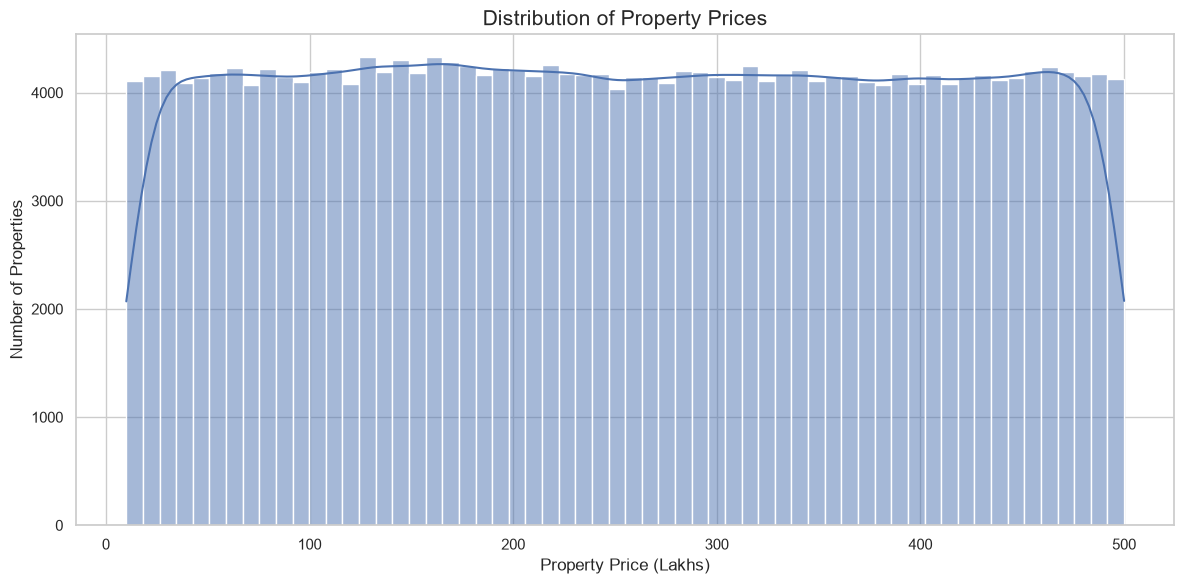

In [5]:
# ==========================================
# PROPERTY PRICE DISTRIBUTION
# ==========================================

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Price_in_Lakhs",
    bins=60,
    kde=True
)

plt.title(
    "Distribution of Property Prices",
    fontsize=15
)

plt.xlabel("Property Price (Lakhs)")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

In [6]:
print("Property Price Analysis")

print("Mean Price:",
      df["Price_in_Lakhs"].mean())

print("Median Price:",
      df["Price_in_Lakhs"].median())

print("Minimum Price:",
      df["Price_in_Lakhs"].min())

print("Maximum Price:",
      df["Price_in_Lakhs"].max())

print("Standard Deviation:",
      df["Price_in_Lakhs"].std())

Property Price Analysis
Mean Price: 254.58685404
Median Price: 253.87
Minimum Price: 10.0
Maximum Price: 500.0
Standard Deviation: 141.349921072615


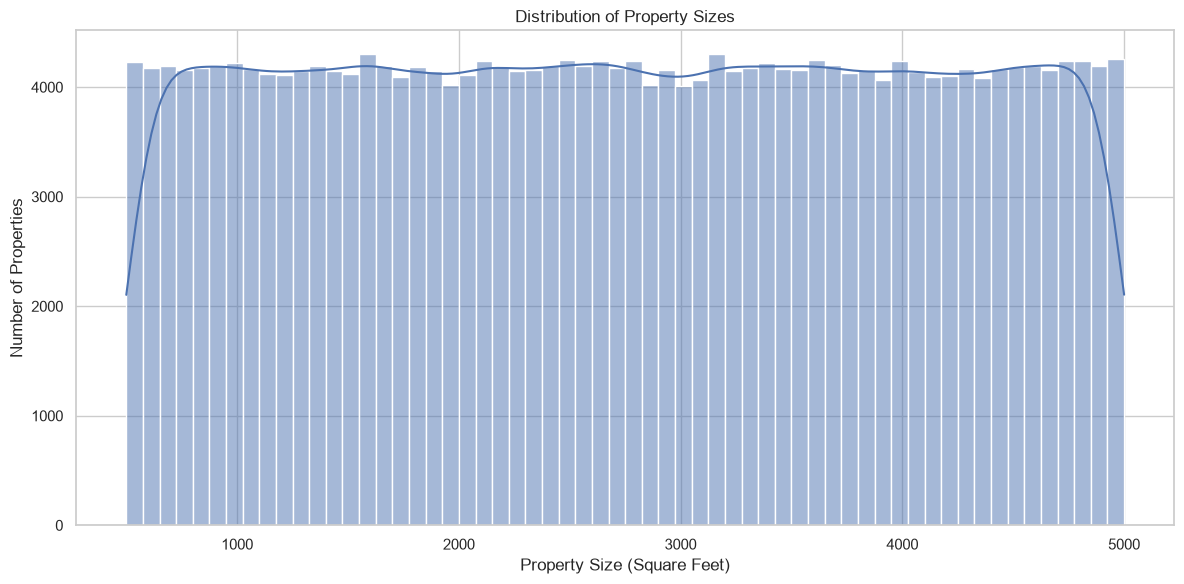

In [7]:
# ==========================================
# PROPERTY SIZE DISTRIBUTION
# ==========================================

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Size_in_SqFt",
    bins=60,
    kde=True
)

plt.title("Distribution of Property Sizes")
plt.xlabel("Property Size (Square Feet)")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

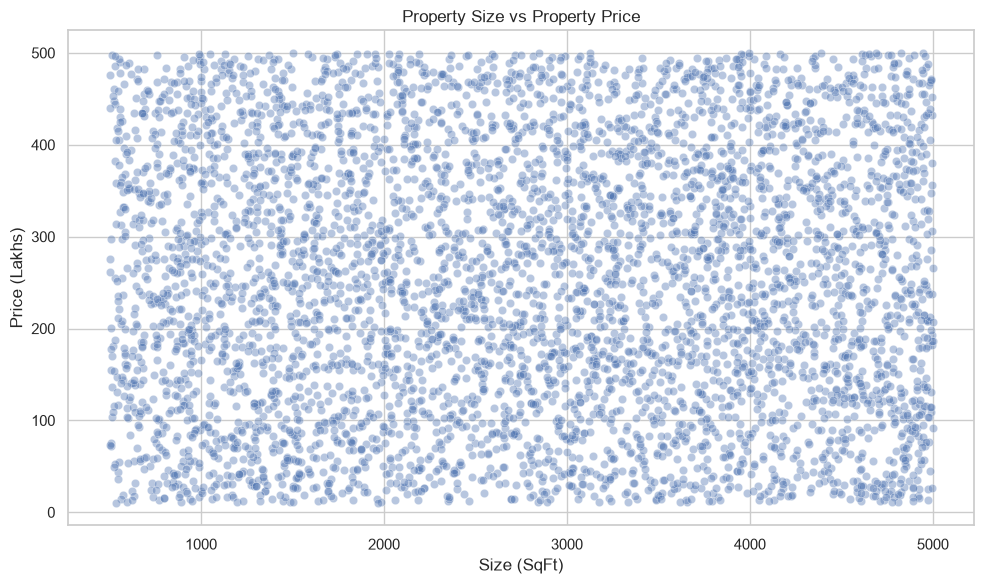

In [8]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df.sample(
        n=min(5000, len(df)),
        random_state=42
    ),
    x="Size_in_SqFt",
    y="Price_in_Lakhs",
    alpha=0.4
)

plt.title("Property Size vs Property Price")
plt.xlabel("Size (SqFt)")
plt.ylabel("Price (Lakhs)")

plt.tight_layout()
plt.show()

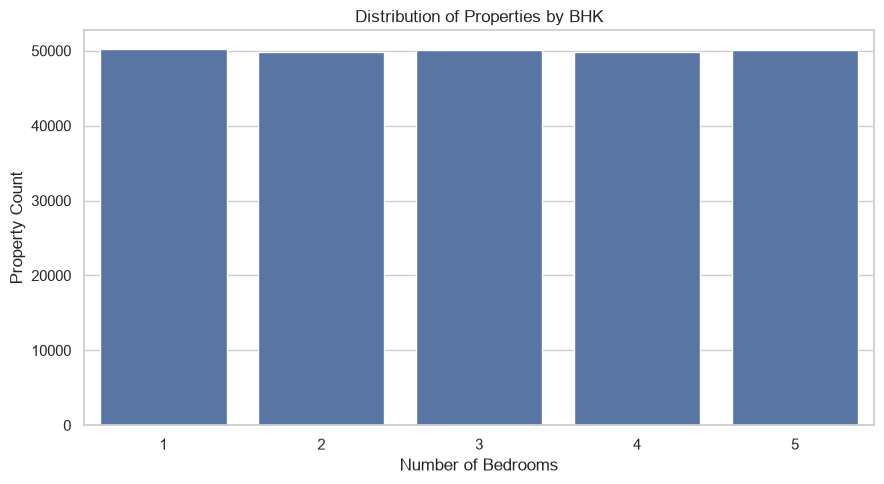

In [9]:
# Number of properties by BHK

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="BHK"
)

plt.title("Distribution of Properties by BHK")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Property Count")

plt.tight_layout()
plt.show()

In [10]:
bhk_analysis = (
    df.groupby("BHK")
    .agg(
        Property_Count=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean")
    )
    .round(2)
)

display(bhk_analysis)

,Property_Count,Average_Price,Median_Price,Average_Size
BHK,,,,
1,50196,254.88,254.06,2749.71
2,49815,254.80,253.30,2751.93
3,50067,254.09,253.13,2750.14
4,49788,254.78,254.92,2752.74
5,50134,254.39,253.86,2744.57


In [11]:
city_analysis = (
    df.groupby("City")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Price_per_SqFt=("Price_per_SqFt", "mean")
    )
    .sort_values(
        by="Average_Price",
        ascending=False
    )
)

display(city_analysis.head(20))

,Total_Properties,Average_Price,Median_Price,Average_Price_per_SqFt
City,,,,
Bangalore,4144,258.456639,258.360,13139.523490
Surat,6167,258.080467,258.230,13377.353654
Kochi,6305,257.415221,258.750,13202.710226
Gaya,6170,257.053391,257.200,13146.404659
Mangalore,4063,256.920925,256.520,13375.351634
Dehradun,6234,256.890115,257.035,13006.164664
Mysore,4217,256.848172,259.520,13244.286189
Chennai,6168,256.830172,256.915,13158.764795
Hyderabad,6273,256.594051,256.780,13228.637301


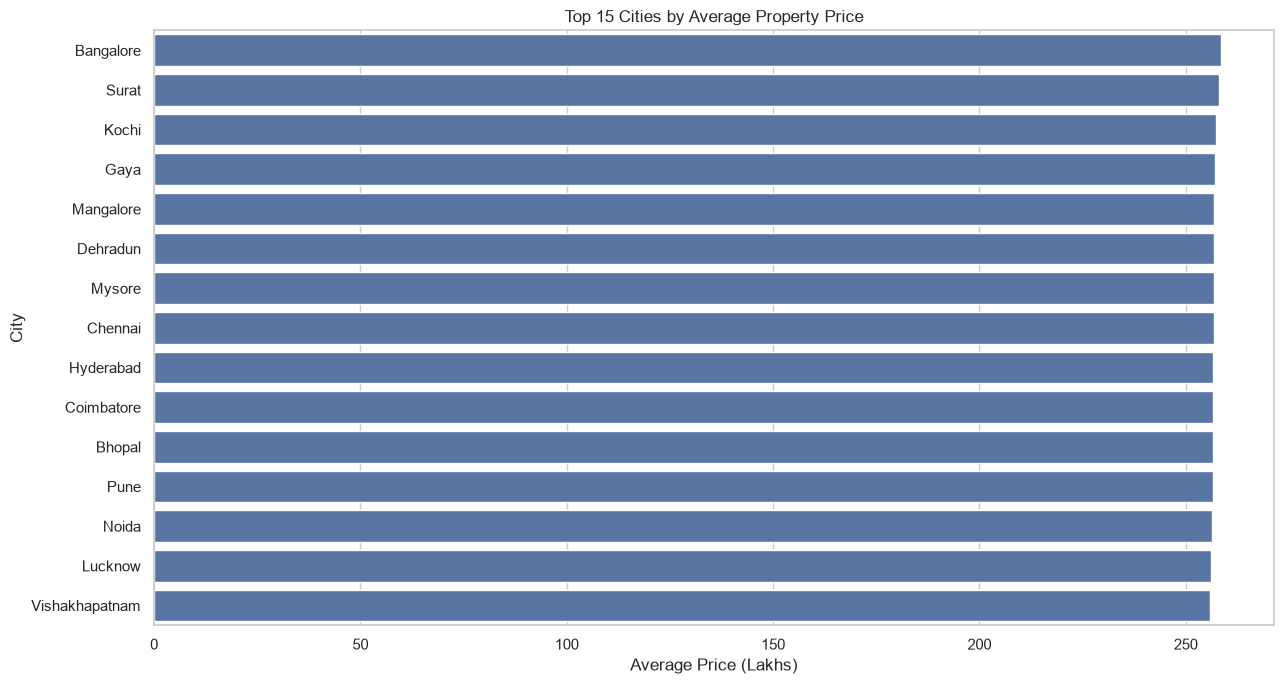

In [12]:
top_cities = city_analysis.head(15).reset_index()

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_cities,
    x="Average_Price",
    y="City"
)

plt.title("Top 15 Cities by Average Property Price")
plt.xlabel("Average Price (Lakhs)")
plt.ylabel("City")

plt.tight_layout()
plt.show()

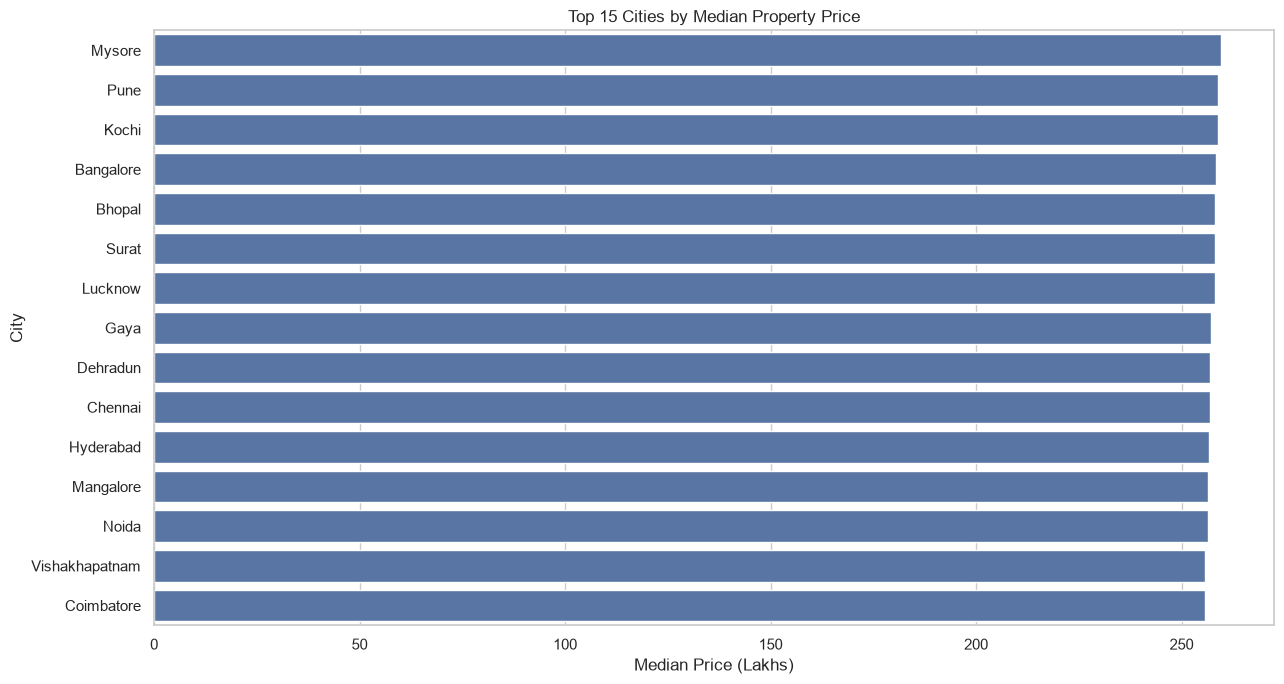

In [13]:
top_median_cities = (
    city_analysis
    .sort_values("Median_Price", ascending=False)
    .head(15)
    .reset_index()
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_median_cities,
    x="Median_Price",
    y="City"
)

plt.title("Top 15 Cities by Median Property Price")
plt.xlabel("Median Price (Lakhs)")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [14]:
property_analysis = (
    df.groupby("Property_Type")
    .agg(
        Property_Count=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_Price_per_SqFt=("Price_per_SqFt", "mean")
    )
    .round(2)
)

display(property_analysis)

,Property_Count,Average_Price,Median_Price,Average_Size,Average_Price_per_SqFt
Property_Type,,,,,
Apartment,82956,254.62,254.02,2751.17,13047.32
Independent House,83300,255.37,255.04,2742.61,13102.05
Villa,83744,253.77,252.54,2755.63,13025.61


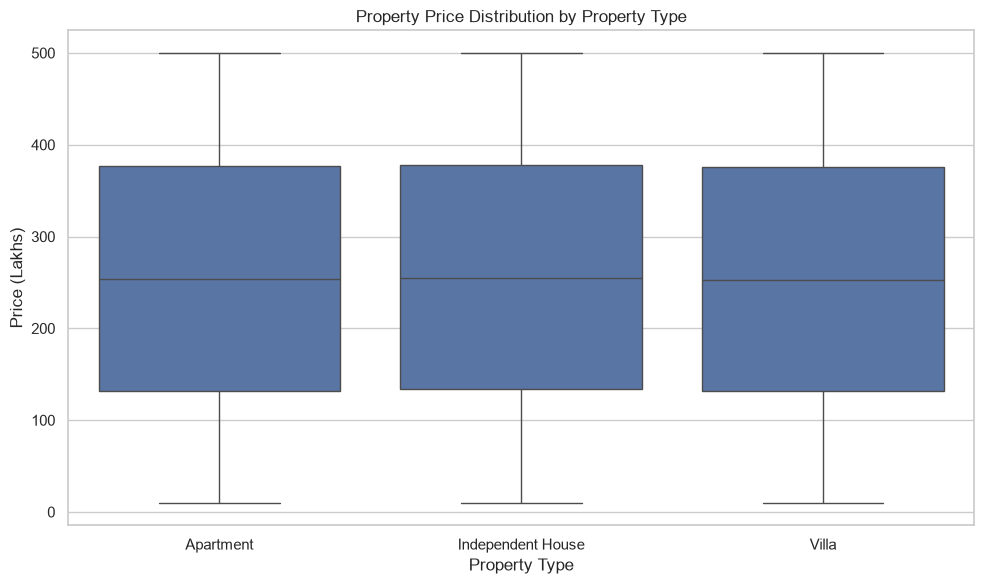

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Property_Type",
    y="Price_in_Lakhs"
)

plt.title("Property Price Distribution by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price (Lakhs)")

plt.tight_layout()
plt.show()

In [16]:
age_analysis = (
    df.groupby("Property_Age_Group", observed=True)
    .agg(
        Property_Count=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median")
    )
    .round(2)
)

display(age_analysis)

,Property_Count,Average_Price,Median_Price
Property_Age_Group,,,
Moderate,73472,254.81,253.42
New,29566,255.73,256.22
Old,110382,254.37,254.10
Very_Old,36580,253.87,251.74


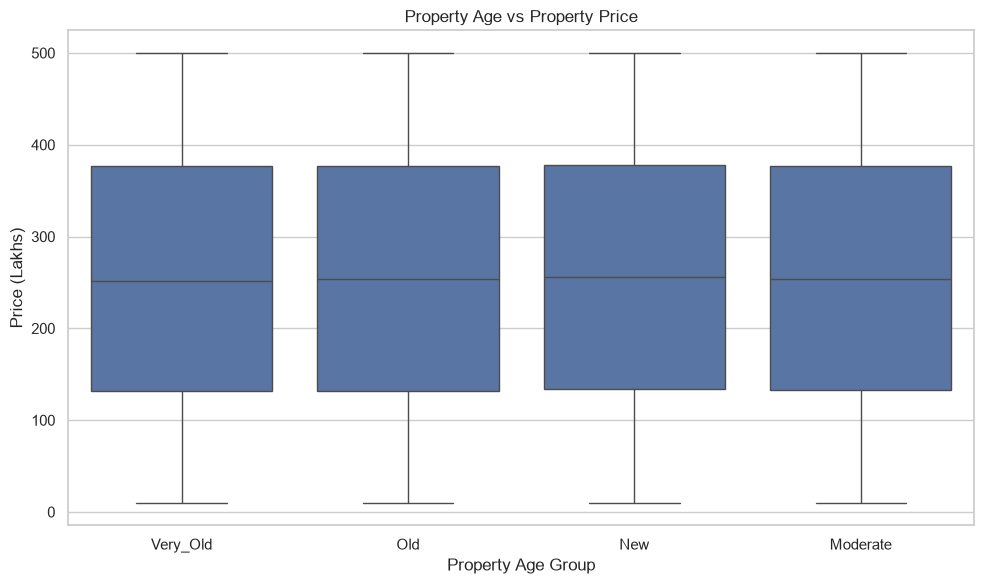

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Property_Age_Group",
    y="Price_in_Lakhs"
)

plt.title("Property Age vs Property Price")
plt.xlabel("Property Age Group")
plt.ylabel("Price (Lakhs)")

plt.tight_layout()
plt.show()

In [18]:
amenity_columns = [
    "Has_Pool",
    "Has_Clubhouse",
    "Has_Garden",
    "Has_Gym",
    "Has_Playground"
]

amenity_analysis = []

for col in amenity_columns:

    with_amenity = df.loc[
        df[col] == 1,
        "Price_in_Lakhs"
    ]

    without_amenity = df.loc[
        df[col] == 0,
        "Price_in_Lakhs"
    ]

    amenity_analysis.append({
        "Amenity": col,
        "Average_Price_With": with_amenity.mean(),
        "Average_Price_Without": without_amenity.mean(),
        "Difference": (
            with_amenity.mean() - without_amenity.mean()
        )
    })

amenity_analysis = pd.DataFrame(amenity_analysis)

display(amenity_analysis.round(2))

,Amenity,Average_Price_With,Average_Price_Without,Difference
0,Has_Pool,254.79,254.28,0.51
1,Has_Clubhouse,254.66,254.48,0.18
2,Has_Garden,254.64,254.50,0.14
3,Has_Gym,254.81,254.25,0.56
4,Has_Playground,254.38,254.90,-0.52


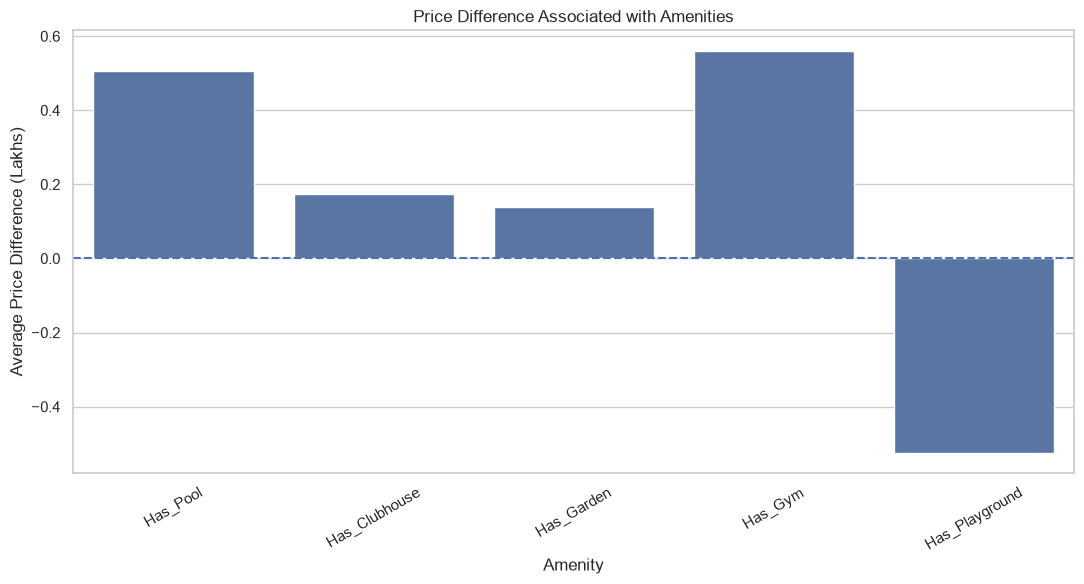

In [19]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=amenity_analysis,
    x="Amenity",
    y="Difference"
)

plt.axhline(0, linestyle="--")

plt.title("Price Difference Associated with Amenities")
plt.xlabel("Amenity")
plt.ylabel("Average Price Difference (Lakhs)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

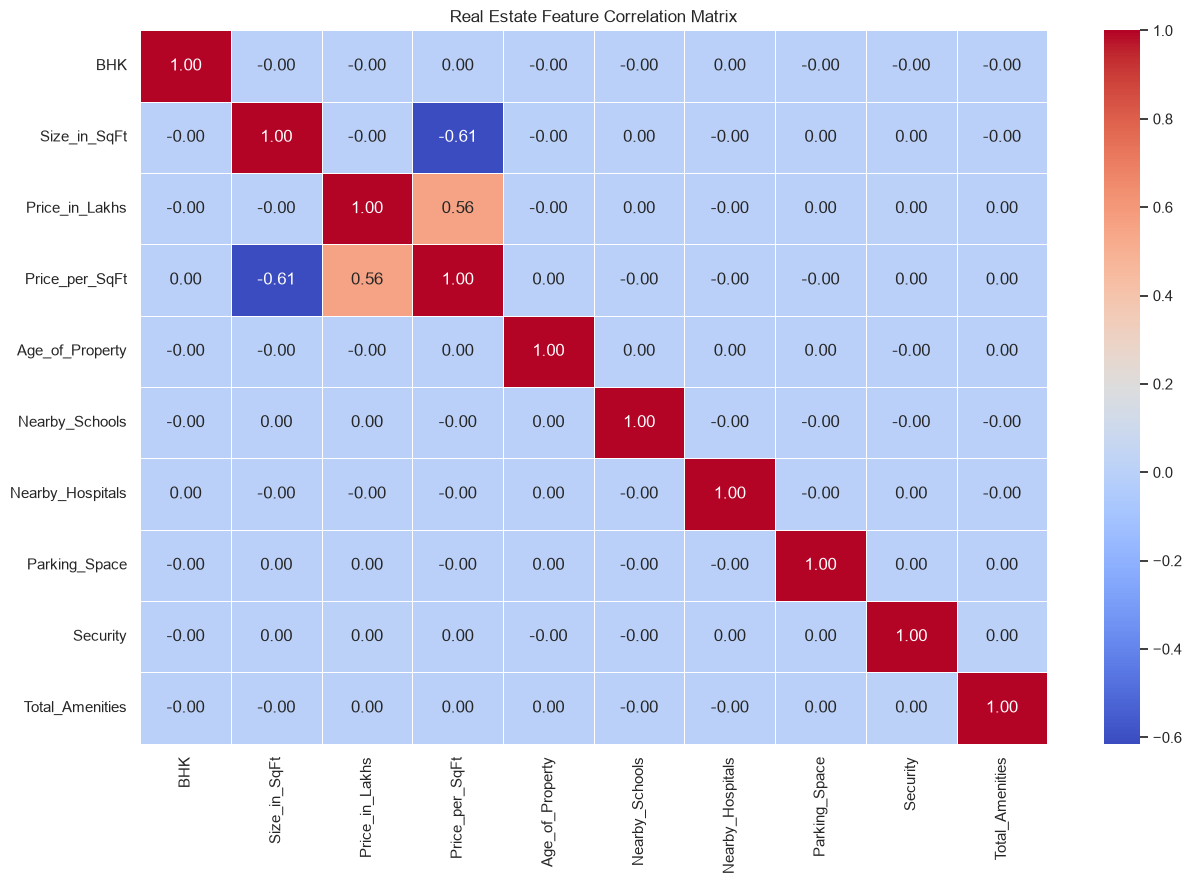

In [20]:
correlation_columns = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Parking_Space",
    "Security",
    "Total_Amenities"
]

correlation_matrix = df[
    correlation_columns
].corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Real Estate Feature Correlation Matrix")

plt.tight_layout()
plt.show()

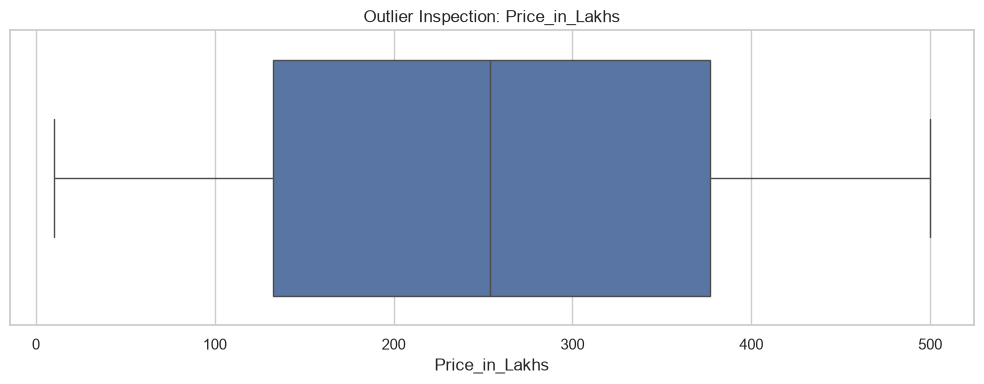

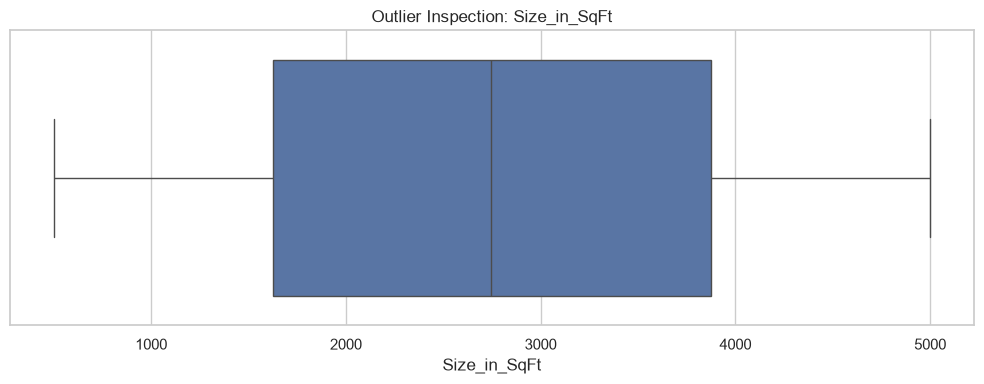

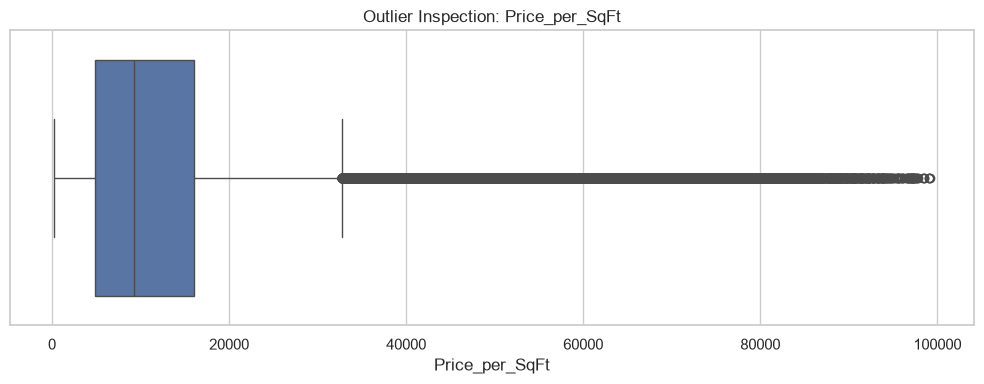

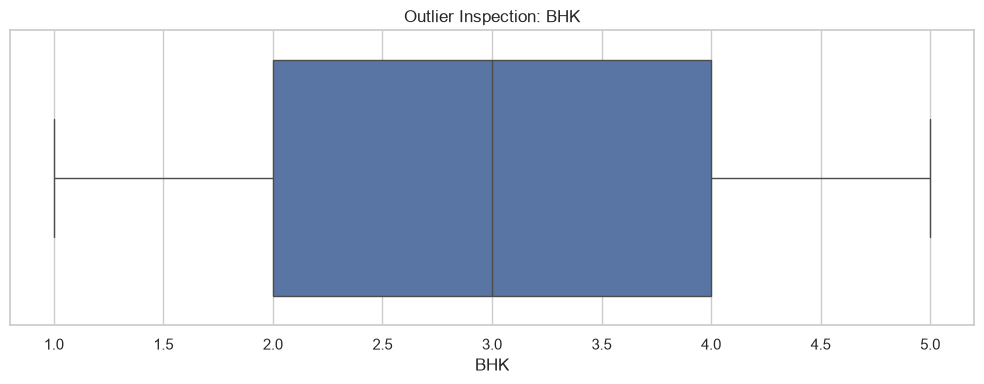

In [21]:
outlier_columns = [
    "Price_in_Lakhs",
    "Size_in_SqFt",
    "Price_per_SqFt",
    "BHK"
]

for col in outlier_columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df[col]
    )

    plt.title(f"Outlier Inspection: {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [22]:
import os

REPORT_PATH = "../reports"

os.makedirs(REPORT_PATH, exist_ok=True)

city_analysis.to_csv(
    f"{REPORT_PATH}/city_price_analysis.csv"
)

property_analysis.to_csv(
    f"{REPORT_PATH}/property_type_analysis.csv"
)

bhk_analysis.to_csv(
    f"{REPORT_PATH}/bhk_analysis.csv"
)

age_analysis.to_csv(
    f"{REPORT_PATH}/property_age_analysis.csv"
)

amenity_analysis.to_csv(
    f"{REPORT_PATH}/amenity_price_analysis.csv",
    index=False
)

correlation_matrix.to_csv(
    f"{REPORT_PATH}/correlation_matrix.csv"
)

print("EDA reports saved successfully!")

EDA reports saved successfully!


In [23]:
# ==========================================
# EDA DIAGNOSTIC - FEATURE RELATIONSHIPS
# ==========================================

print("PRICE CORRELATION WITH IMPORTANT FEATURES")

diagnostic_columns = [
    "Price_in_Lakhs",
    "Size_in_SqFt",
    "BHK",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Total_Amenities"
]

display(
    df[diagnostic_columns]
    .corr()["Price_in_Lakhs"]
    .sort_values(ascending=False)
)

print("\nAVERAGE PRICE BY BHK")

display(
    df.groupby("BHK")["Price_in_Lakhs"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("\nPRICE DISTRIBUTION")

display(
    df["Price_in_Lakhs"]
    .value_counts(bins=10)
    .sort_index()
)

PRICE CORRELATION WITH IMPORTANT FEATURES


Price_in_Lakhs      1.000000
Total_Amenities     0.001029
Nearby_Schools      0.000155
BHK                -0.000980
Size_in_SqFt       -0.002529
Age_of_Property    -0.002714
Nearby_Hospitals   -0.002769
Name: Price_in_Lakhs, dtype: float64


AVERAGE PRICE BY BHK


,count,mean,median,std
BHK,,,,
1,50196,254.88,254.06,141.36
2,49815,254.80,253.30,141.29
3,50067,254.09,253.13,141.29
4,49788,254.78,254.92,141.35
5,50134,254.39,253.86,141.46



PRICE DISTRIBUTION


(9.509, 59.0]     24894
(59.0, 108.0]     24952
(108.0, 157.0]    25299
(157.0, 206.0]    25465
(206.0, 255.0]    24945
(255.0, 304.0]    24900
(304.0, 353.0]    24943
(353.0, 402.0]    24725
(402.0, 451.0]    24789
(451.0, 500.0]    25088
Name: count, dtype: int64

In [24]:
# ==========================================
# CITY-WISE PRICE ANALYSIS
# ==========================================

city_analysis = (
    df.groupby("City")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .round(2)
    .sort_values(
        by="Average_Price",
        ascending=False
    )
)

display(city_analysis.head(20))

,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK
City,,,,,
Bangalore,4144,258.46,258.36,2749.87,3.01
Surat,6167,258.08,258.23,2734.76,2.99
Kochi,6305,257.42,258.75,2766.79,3.01
Gaya,6170,257.05,257.20,2766.81,2.95
Mangalore,4063,256.92,256.52,2722.90,2.99
Dehradun,6234,256.89,257.03,2757.30,2.99
Mysore,4217,256.85,259.52,2746.08,2.99
Chennai,6168,256.83,256.91,2768.13,2.99
Hyderabad,6273,256.59,256.78,2747.13,3.01


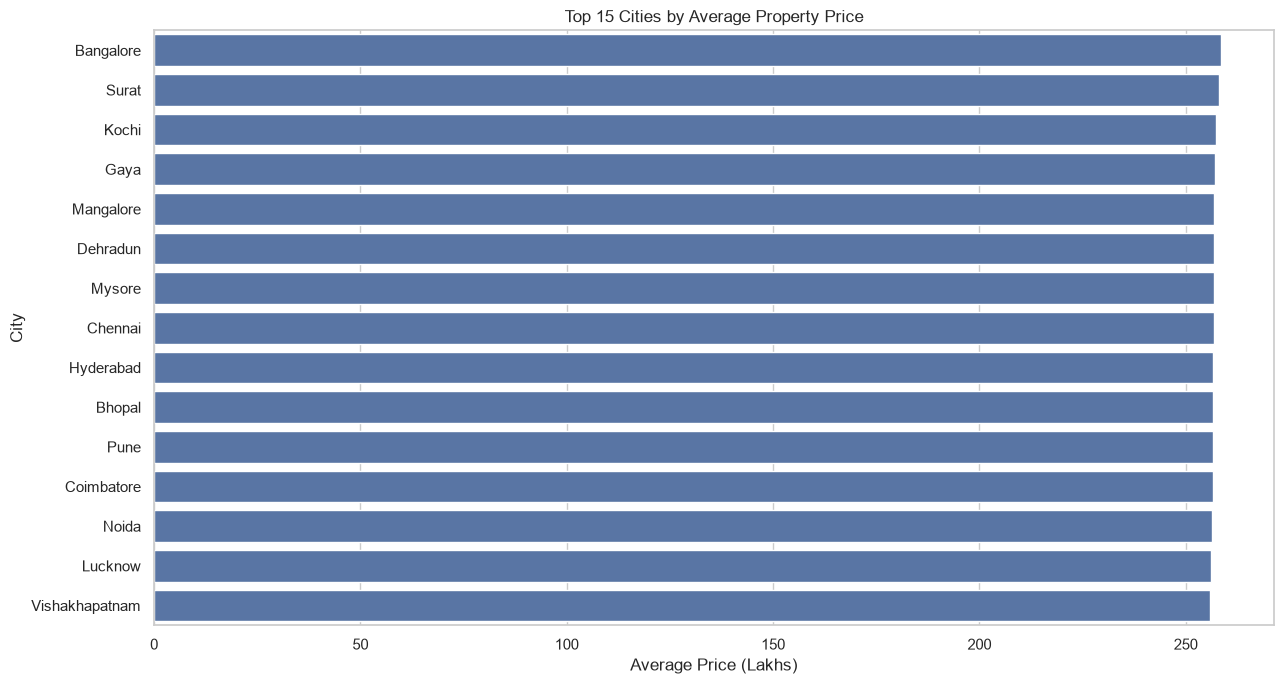

In [25]:
plt.figure(figsize=(13, 7))

sns.barplot(
    data=city_analysis.head(15).reset_index(),
    x="Average_Price",
    y="City"
)

plt.title("Top 15 Cities by Average Property Price")
plt.xlabel("Average Price (Lakhs)")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# GEOGRAPHICAL PRICE VARIATION ANALYSIS
# ==========================================

# City-level price statistics

city_variation = (
    df.groupby("City")
    ["Price_in_Lakhs"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print("CITY PRICE VARIATION")

display(
    city_variation.sort_values(
        "mean",
        ascending=False
    )
)

# Overall city average range

print("\nHighest City Average:")
print(city_variation["mean"].max())

print("\nLowest City Average:")
print(city_variation["mean"].min())

print("\nDifference:")
print(
    city_variation["mean"].max()
    - city_variation["mean"].min()
)

CITY PRICE VARIATION


,count,mean,median,std,min,max
City,,,,,,
Bangalore,4144,258.46,258.36,141.26,10.11,499.94
Surat,6167,258.08,258.23,142.05,10.19,499.99
Kochi,6305,257.42,258.75,141.48,10.05,499.85
Gaya,6170,257.05,257.20,141.90,10.16,499.91
Mangalore,4063,256.92,256.52,142.94,10.06,499.90
Dehradun,6234,256.89,257.03,141.37,10.13,499.97
Mysore,4217,256.85,259.52,140.12,10.15,499.86
Chennai,6168,256.83,256.91,140.58,10.04,499.95
Hyderabad,6273,256.59,256.78,139.95,10.31,499.95



Highest City Average:
258.46

Lowest City Average:
250.79

Difference:
7.6699999999999875


In [34]:
# ==========================================
# LOCALITY PRICE ANALYSIS
# ==========================================

locality_analysis = (
    df.groupby(["City", "Locality"])
    .agg(
        Property_Count=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean")
    )
    .reset_index()
)

# Focus on localities with at least 100 properties

locality_analysis = locality_analysis[
    locality_analysis["Property_Count"] >= 100
]

locality_analysis = locality_analysis.sort_values(
    "Average_Price",
    ascending=False
)

display(locality_analysis.head(20))

,City,Locality,Property_Count,Average_Price,Median_Price,Average_Size


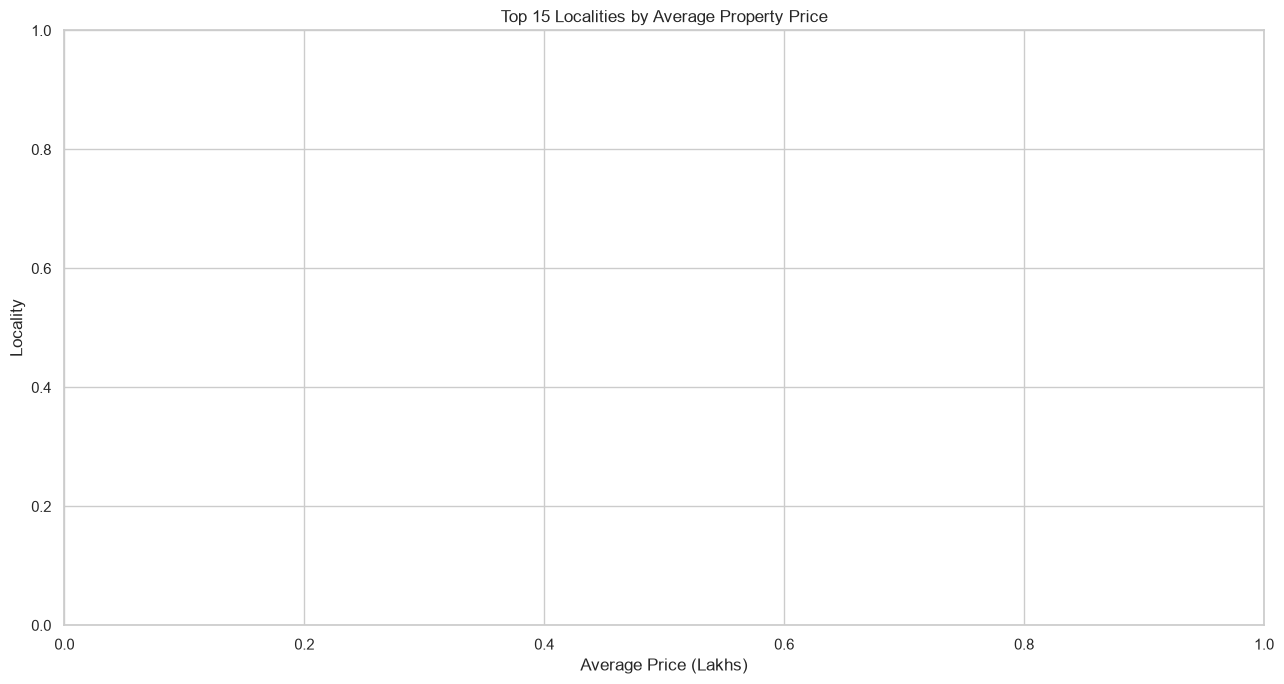

In [38]:
plt.figure(figsize=(13, 7))

top_localities = locality_analysis.head(15)

sns.barplot(
    data=top_localities,
    x="Average_Price",
    y="Locality"
)

plt.title("Top 15 Localities by Average Property Price")
plt.xlabel("Average Price (Lakhs)")
plt.ylabel("Locality")

plt.tight_layout()
plt.show()


In [39]:
# ==========================================
# PRICE VARIATION BY PROPERTY FEATURES
# ==========================================

feature_groups = [
    "Property_Type",
    "Furnished_Status",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

for col in feature_groups:

    print(f"\n{'=' * 50}")
    print(f"PRICE ANALYSIS BY {col}")
    print("=" * 50)

    result = (
        df.groupby(col, observed=True)
        ["Price_in_Lakhs"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )

    display(result)


PRICE ANALYSIS BY Property_Type


,count,mean,median,std
Property_Type,,,,
Apartment,82956,254.62,254.02,141.71
Independent House,83300,255.37,255.04,141.20
Villa,83744,253.77,252.54,141.15



PRICE ANALYSIS BY Furnished_Status


,count,mean,median,std
Furnished_Status,,,,
Furnished,83218,254.45,253.56,141.20
Semi-furnished,83374,254.33,253.81,141.45
Unfurnished,83408,254.98,254.19,141.40



PRICE ANALYSIS BY Public_Transport_Accessibility


,count,mean,median,std
Public_Transport_Accessibility,,,,
High,83705,254.92,254.71,141.50
Low,83287,254.86,254.27,141.24
Medium,83008,253.97,252.73,141.30


... (6 outputs left out)


PRICE ANALYSIS BY Owner_Type


,count,mean,median,std
Owner_Type,,,,
Broker,83479,254.91,254.90,141.54
Builder,83253,254.59,253.67,141.19
Owner,83268,254.25,253.00,141.31



PRICE ANALYSIS BY Availability_Status


,count,mean,median,std
Availability_Status,,,,
Ready_to_Move,124965,254.98,254.31,141.09
Under_Construction,125035,254.19,253.48,141.61


In [40]:
# ==========================================
# LOCALITY DISTRIBUTION INVESTIGATION
# ==========================================

# Check number of unique localities
print("Unique localities:", df["Locality"].nunique())

# Group by City and Locality
locality_counts = (
    df.groupby(["City", "Locality"])
    .size()
    .reset_index(name="Property_Count")
)

print("\nCity-Locality combinations:")
print(len(locality_counts))

print("\nProperty count distribution:")
display(locality_counts["Property_Count"].describe())

print("\nTop 20 City-Locality combinations:")

display(
    locality_counts.sort_values(
        "Property_Count",
        ascending=False
    ).head(20)
)

# Check whether locality labels appear in multiple cities
locality_city_count = (
    df.groupby("Locality")["City"]
    .nunique()
)

print(
    "\nLocalities appearing in multiple cities:",
    (locality_city_count > 1).sum()
)

Unique localities: 500

City-Locality combinations:
20999

Property count distribution:


count    20999.000000
mean        11.905329
std          3.792201
min          1.000000
25%          9.000000
50%         12.000000
75%         14.000000
max         29.000000
Name: Property_Count, dtype: float64


Top 20 City-Locality combinations:


,City,Locality,Property_Count
11046,Kochi,Locality_140,29
19015,Trivandrum,Locality_113,29
3675,Coimbatore,Locality_257,28
10423,Jamshedpur,Locality_480,28
15032,New Delhi,Locality_129,27
19071,Trivandrum,Locality_164,27
17651,Ranchi,Locality_236,27
20887,Warangal,Locality_449,27
9472,Indore,Locality_74,26
9132,Indore,Locality_218,26



Localities appearing in multiple cities: 500


In [42]:
locality_analysis["Property_Count"] >= 100

11063    False
12208    False
19899    False
7222     False
8693     False
         ...  
18280    False
3928     False
9502     False
19316    False
19069    False
Name: Property_Count, Length: 575, dtype: bool

In [43]:
# ==========================================
# CORRECTED LOCALITY PRICE ANALYSIS
# ==========================================

locality_analysis = (
    df.groupby(["City", "Locality"])
    .agg(
        Property_Count=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean")
    )
    .reset_index()
)

# Minimum 20 properties
locality_analysis = locality_analysis[
    locality_analysis["Property_Count"] >= 20
].copy()

locality_analysis = locality_analysis.sort_values(
    "Average_Price",
    ascending=False
)

print("Qualified locality combinations:",
      len(locality_analysis))

display(locality_analysis.head(20))

Qualified locality combinations: 575


,City,Locality,Property_Count,Average_Price,Median_Price,Average_Size
11063,Kochi,Locality_156,20,340.556000,373.320,2335.400000
12208,Lucknow,Locality_287,21,331.342857,331.490,2935.142857
19899,Vijayawada,Locality_46,21,330.642381,365.750,2829.619048
7222,Gurgaon,Locality_3,20,327.064500,365.665,2724.250000
8693,Hyderabad,Locality_273,21,323.888095,364.670,2536.047619
20375,Vishakhapatnam,Locality_438,20,321.069500,344.465,2791.350000
19196,Trivandrum,Locality_277,20,319.365000,327.470,3200.600000
16356,Patna,Locality_420,20,318.698000,390.090,2723.050000
2340,Bhubaneswar,Locality_405,21,318.517143,357.500,2820.666667
11101,Kochi,Locality_190,21,318.427619,359.780,2390.571429


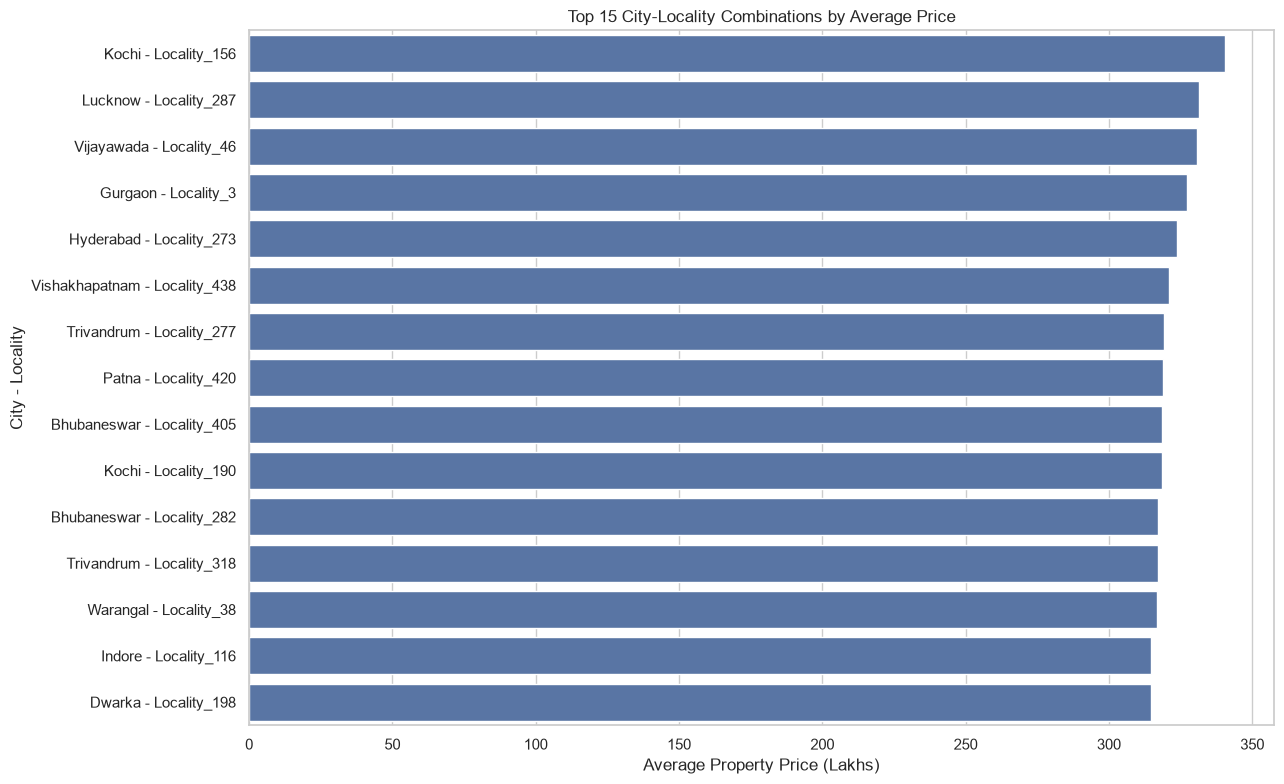

In [44]:
# ==========================================
# TOP 15 CITY-LOCALITY PRICE COMBINATIONS
# ==========================================

top_localities = locality_analysis.head(15).copy()

top_localities["Location"] = (
    top_localities["City"]
    + " - "
    + top_localities["Locality"]
)

plt.figure(figsize=(13, 8))

sns.barplot(
    data=top_localities,
    x="Average_Price",
    y="Location"
)

plt.title("Top 15 City-Locality Combinations by Average Price")
plt.xlabel("Average Property Price (Lakhs)")
plt.ylabel("City - Locality")

plt.tight_layout()
plt.show()

In [45]:
# ==========================================
# LOCALITY PRICE VARIATION
# ==========================================

print("Locality Price Statistics")

display(
    locality_analysis["Average_Price"].describe()
)

print("\nHighest Locality Average Price:")

print(
    locality_analysis["Average_Price"].max()
)

print("\nLowest Locality Average Price:")

print(
    locality_analysis["Average_Price"].min()
)

print("\nPrice Difference:")

print(
    locality_analysis["Average_Price"].max()
    - locality_analysis["Average_Price"].min()
)

Locality Price Statistics


count    575.000000
mean     253.090449
std       30.729303
min      137.436667
25%      232.003302
50%      253.457917
75%      272.690000
max      340.556000
Name: Average_Price, dtype: float64


Highest Locality Average Price:
340.556

Lowest Locality Average Price:
137.43666666666667

Price Difference:
203.11933333333332


In [46]:
# ==========================================
# OUTLIER DETECTION USING IQR
# ==========================================

numerical_columns = [
    "Price_in_Lakhs",
    "Size_in_SqFt",
    "BHK",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Price_per_SqFt",
    "Total_Amenities"
]

outlier_results = []

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(df) * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Price_in_Lakhs,132.55,376.88,244.33,-233.94,743.38,0,0.00
1,Size_in_SqFt,1623.00,3874.00,2251.00,-1753.50,7250.50,0,0.00
2,BHK,2.00,4.00,2.00,-1.00,7.00,0,0.00
3,Age_of_Property,10.00,27.00,17.00,-15.50,52.50,0,0.00
4,Nearby_Schools,3.00,8.00,5.00,-4.50,15.50,0,0.00
5,Nearby_Hospitals,3.00,8.00,5.00,-4.50,15.50,0,0.00
6,Price_per_SqFt,4802.84,15987.39,11184.55,-11973.98,32764.21,19723,7.89
7,Total_Amenities,2.00,4.00,2.00,-1.00,7.00,0,0.00


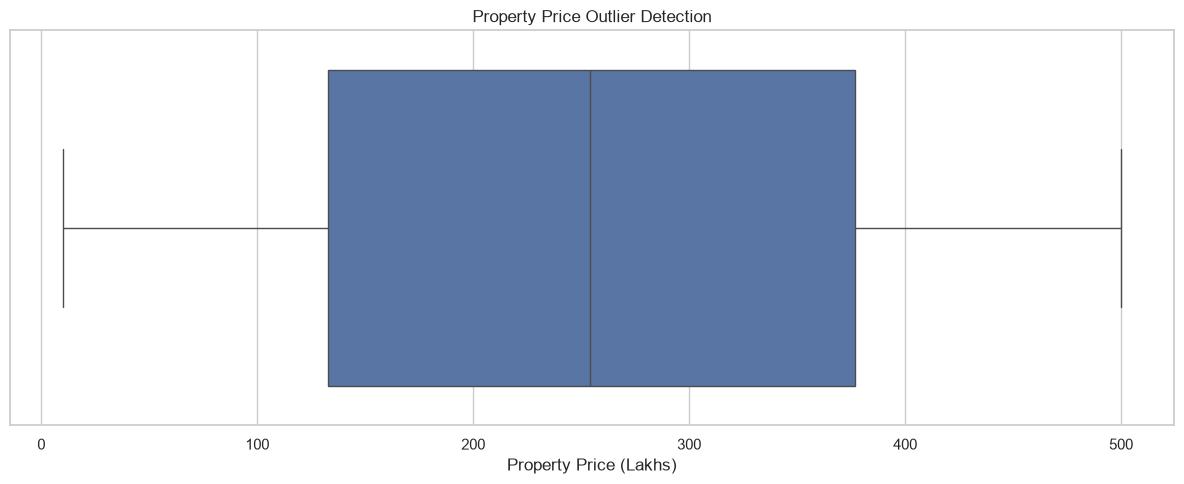

In [47]:
# ==========================================
# PROPERTY PRICE BOXPLOT
# ==========================================

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df["Price_in_Lakhs"]
)

plt.title("Property Price Outlier Detection")
plt.xlabel("Property Price (Lakhs)")

plt.tight_layout()
plt.show()

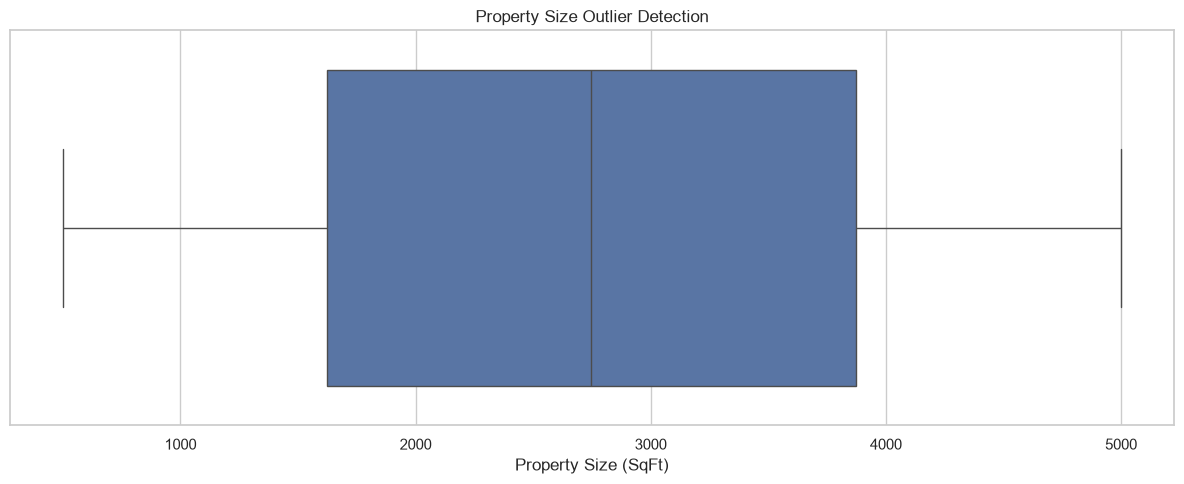

In [48]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df["Size_in_SqFt"]
)

plt.title("Property Size Outlier Detection")
plt.xlabel("Property Size (SqFt)")

plt.tight_layout()
plt.show()

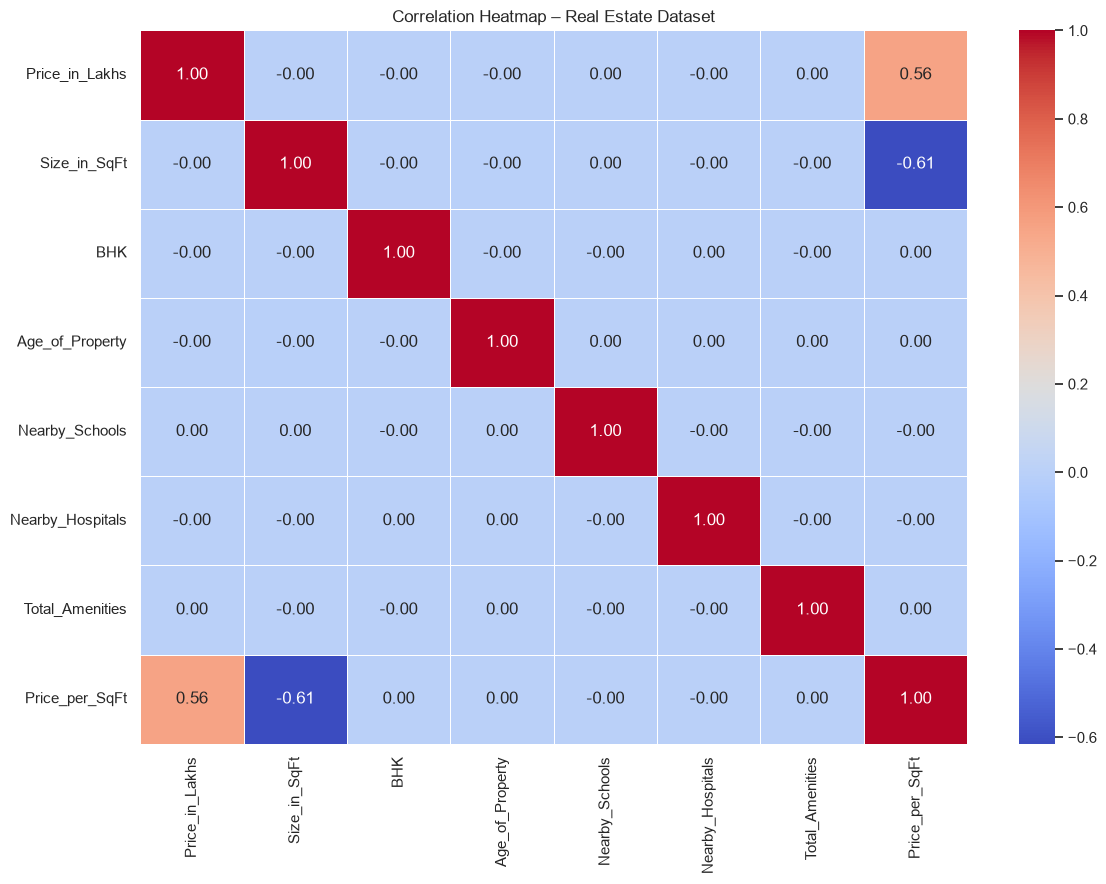

In [49]:
# ==========================================
# NUMERICAL FEATURE CORRELATION
# ==========================================

correlation_columns = [
    "Price_in_Lakhs",
    "Size_in_SqFt",
    "BHK",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Total_Amenities",
    "Price_per_SqFt"
]

correlation_matrix = df[
    correlation_columns
].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap – Real Estate Dataset")

plt.tight_layout()
plt.show()

In [50]:
# ==========================================
# CATEGORICAL FEATURE vs PROPERTY PRICE
# ==========================================

categorical_columns = [
    "State",
    "City",
    "Property_Type",
    "Furnished_Status",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

results = []

overall_mean = df["Price_in_Lakhs"].mean()

total_variation = (
    (df["Price_in_Lakhs"] - overall_mean) ** 2
).sum()

for col in categorical_columns:

    grouped = df.groupby(col)["Price_in_Lakhs"]

    group_means = grouped.mean()
    group_counts = grouped.size()

    between_variation = (
        group_counts *
        (group_means - overall_mean) ** 2
    ).sum()

    eta_squared = between_variation / total_variation

    results.append({
        "Feature": col,
        "Unique_Values": df[col].nunique(),
        "Eta_Squared": eta_squared,
        "Explained_Variation_Percent": eta_squared * 100
    })

categorical_analysis = pd.DataFrame(results)

categorical_analysis = categorical_analysis.sort_values(
    "Explained_Variation_Percent",
    ascending=False
)

display(categorical_analysis.round(4))

,Feature,Unique_Values,Eta_Squared,Explained_Variation_Percent
1,City,42,0.0002,0.0190
0,State,20,0.0001,0.0097
2,Property_Type,3,0.0000,0.0022
6,Security,2,0.0000,0.0015
4,Public_Transport_Accessibility,3,0.0000,0.0009
9,Availability_Status,2,0.0000,0.0008
7,Facing,4,0.0000,0.0006
3,Furnished_Status,3,0.0000,0.0004
8,Owner_Type,3,0.0000,0.0004
5,Parking_Space,2,0.0000,0.0001


TARGET VARIABLE ANALYSIS
Unique prices: 48700
Minimum price: 10.0
Maximum price: 500.0
Mean price: 254.58685404
Median price: 253.87
Standard deviation: 141.349921072615
Skewness: 0.008205884031129845
Number of unique price values: 48700
Number of repeated price values: 201300


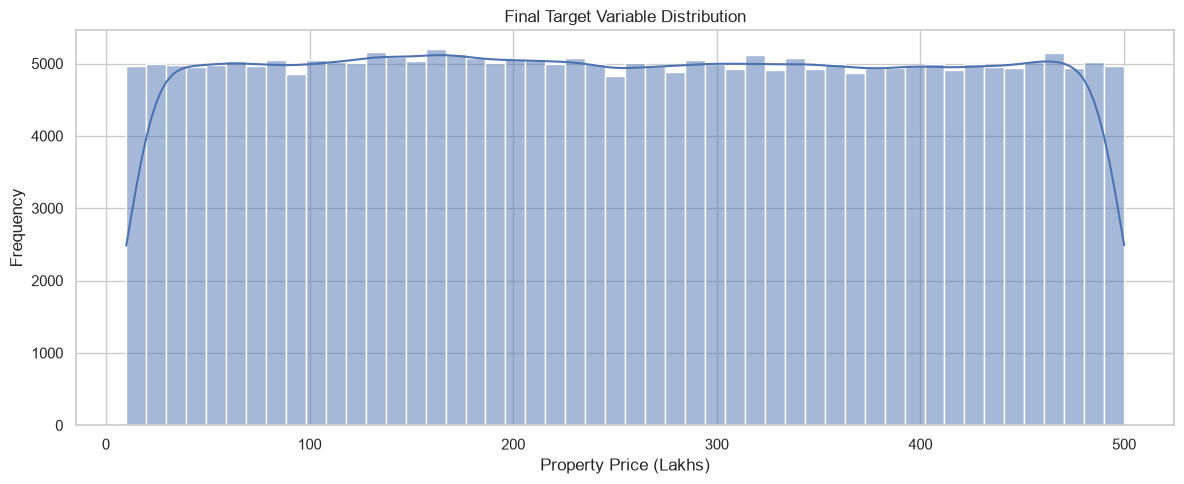

In [51]:
# ==========================================
# FINAL TARGET VARIABLE INVESTIGATION
# ==========================================

target = df["Price_in_Lakhs"]

print("TARGET VARIABLE ANALYSIS")
print("=" * 45)

print("Unique prices:", target.nunique())

print("Minimum price:", target.min())

print("Maximum price:", target.max())

print("Mean price:", target.mean())

print("Median price:", target.median())

print("Standard deviation:", target.std())

print(
    "Skewness:",
    target.skew()
)

print(
    "Number of unique price values:",
    target.nunique()
)

print(
    "Number of repeated price values:",
    target.duplicated().sum()
)

plt.figure(figsize=(12, 5))

sns.histplot(
    target,
    bins=50,
    kde=True
)

plt.title("Final Target Variable Distribution")

plt.xlabel("Property Price (Lakhs)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [52]:
# ==========================================
# FINAL DATASET RELATIONSHIP VALIDATION
# ==========================================

features = [
    "Size_in_SqFt",
    "BHK",
    "Year_Built",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Parking_Space",
    "Security",
    "Total_Amenities"
]

# Calculate Pearson and Spearman correlations

relationship_check = pd.DataFrame({
    "Pearson": df[features].corrwith(
        df["Price_in_Lakhs"],
        method="pearson"
    ),
    "Spearman": df[features].corrwith(
        df["Price_in_Lakhs"],
        method="spearman"
    )
})

display(
    relationship_check.round(4)
)

# Compare price ranges by property size

df["Size_Group"] = pd.qcut(
    df["Size_in_SqFt"],
    q=5,
    labels=[
        "Very Small",
        "Small",
        "Medium",
        "Large",
        "Very Large"
    ]
)

size_price_check = (
    df.groupby("Size_Group", observed=True)
    ["Price_in_Lakhs"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(size_price_check)

,Pearson,Spearman
Size_in_SqFt,-0.0025,-0.0025
BHK,-0.0010,-0.0010
Year_Built,0.0027,0.0027
Age_of_Property,-0.0027,-0.0027
Nearby_Schools,0.0002,0.0001
Nearby_Hospitals,-0.0028,-0.0028
Parking_Space,0.0011,0.0011
Security,0.0038,0.0038
Total_Amenities,0.0010,0.0010


,count,mean,median,std
Size_Group,,,,
Very Small,50010,255.65,255.83,141.24
Small,50007,254.57,254.65,141.50
Medium,50006,253.59,252.84,141.35
Large,49978,254.57,252.56,141.10
Very Large,49999,254.55,253.24,141.56
